# Setup

In [1]:
import os
import pandas as pd
import qiime2 as q2
from skbio import OrdinationResults
from qiime2 import Visualization
from seaborn import scatterplot

%matplotlib inline

In [8]:
pcoa_dir="../../output/exploratory_diversity/"
data_dir="../../data/"

# fetch data

In [3]:
pcs = q2.Artifact.load(os.path.join(pcoa_dir, 'bray_curtis_pcoa_results.qza'))
pcs = pcs.view(OrdinationResults)
# let's just take the first 3 columns (i.e., first 3 PCoA axes)
pcs_data = pcs.samples.iloc[:,:3]
# rename the columns for clarity
pcs_data.columns = ['Axis 1', 'Axis 2', 'Axis 3']

In [4]:
pcs_data.head()

,Axis 1,Axis 2,Axis 3
SRR25052449,0.032948,0.331561,0.004263
SRR25052450,-0.384933,-0.046253,-0.082462
SRR25052451,0.133895,-0.018618,0.455263
SRR25052452,-0.047512,-0.110301,0.359923
SRR25052453,-0.512772,-0.288261,-0.082704


# incorporate metadata

In [9]:
metadata=pd.read_csv(f"{data_dir}metadata.tsv", sep="\t")

In [14]:
metadata.head()

,del,collection_date,country,instrument,sample_id,delivery_mode,host_sex,diet_milk,city,latitude,longitude,urca_code,urca_description,host_id,host_age,seq_depth
0,SRR25052523,19.09.2018,usa,illumina novaseq 6000,1,csection,female,NaN,falls church,38.86,-77.23,9,<1 hour to large city (1 - 5 million),10,2 months,17325587
1,SRR25052512,20.12.2018,usa,illumina novaseq 6000,2,csection,female,mixed,falls church,38.86,-77.23,9,<1 hour to large city (1 - 5 million),10,6 months,12407450
2,SRR25052501,08.07.2019,usa,illumina novaseq 6000,3,csection,female,mixed,falls church,38.86,-77.23,9,<1 hour to large city (1 - 5 million),10,12 months,11964978
3,SRR25052458,30.06.2020,usa,illumina novaseq 6000,4,csection,female,mixed,falls church,38.86,-77.23,9,<1 hour to large city (1 - 5 million),10,24 months,10921526
4,SRR25052720,28.08.2018,usa,illumina novaseq 6000,5,vaginal,male,NaN,falls church,38.86,-77.23,9,<1 hour to large city (1 - 5 million),105,birth,12988703


In [26]:
pcs_data_with_md = pd.concat([pcs_data, metadata.set_index(metadata.columns[0])['host_age']], axis=1, join='inner')
pcs_data_with_md

,Axis 1,Axis 2,Axis 3,host_age
SRR25052449,0.032948,0.331561,0.004263,24 months
SRR25052450,-0.384933,-0.046253,-0.082462,12 months
SRR25052451,0.133895,-0.018618,0.455263,6 months
SRR25052452,-0.047512,-0.110301,0.359923,2 months
SRR25052453,-0.512772,-0.288261,-0.082704,birth
...,...,...,...,...
SRR25052715,-0.505113,-0.281003,-0.084687,birth
SRR25052716,0.023652,0.171876,-0.032584,24 months
SRR25052717,0.206096,0.177656,-0.143330,2 months
SRR25052719,-0.400869,-0.148307,-0.070530,2 months


# plot

<Axes: xlabel='Axis 2', ylabel='Axis 3'>

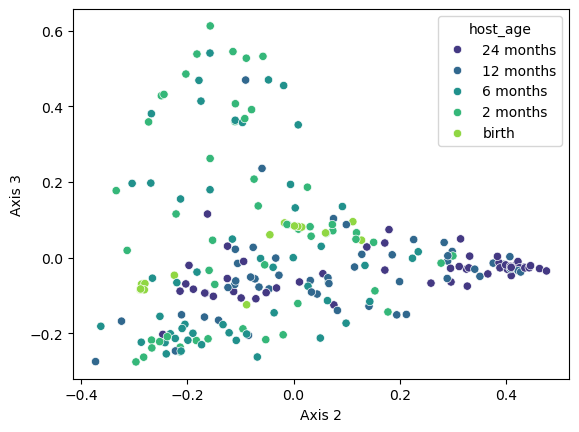

In [31]:
scatterplot(data=pcs_data_with_md,
            x='Axis 2',
            y='Axis 3',
            hue='host_age',
            palette='viridis')